In [1]:
!pip install catboost xgboost lightgbm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv1D, MaxPooling1D, LSTM, BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings('ignore')
print("Kurulum tamamlandı ve kütüphaneler yüklendi.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.0 MB/s eta 0:00:00
Kurulum tamamlandı ve kütüphaneler yüklendi.


In [2]:
file_path = 'Time_domain_subsamples.csv'

print("Veri yükleniyor...")
df = pd.read_csv(file_path, header=None)

print(f"Ham Veri Boyutu: {df.shape}")

X_raw = df.iloc[:, 0:1800].values
y_raw = df.iloc[:, 1800].values

print(f"X (Features) Boyutu: {X_raw.shape}")
print(f"y (Labels) Boyutu: {y_raw.shape}")

classes = np.unique(y_raw)
print(f"Sınıflar: {classes}")
print(f"Toplam Sınıf Sayısı: {len(classes)}")

Veri yükleniyor...
Ham Veri Boyutu: (20750, 1803)
X (Features) Boyutu: (20750, 1800)
y (Labels) Boyutu: (20750,)
Sınıflar: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Toplam Sınıf Sayısı: 18


In [3]:
def calculate_entropy(signal):
    """Sinyal entropisi hesaplar"""
    counts, _ = np.histogram(signal, bins=10, density=True)
    counts = counts[counts > 0]
    return stats.entropy(counts)

def extract_features(data):
    features_list = []

    data_reshaped = data.reshape(data.shape[0], 6, 300)

    for sample in data_reshaped:
        sample_features = []
        for axis in sample:
            sample_features.append(np.mean(axis))
            sample_features.append(np.max(axis))
            sample_features.append(np.min(axis))
            sample_features.append(np.median(axis))
            sample_features.append(np.std(axis))
            sample_features.append(stats.skew(axis))
            sample_features.append(stats.kurtosis(axis))
            sample_features.append(np.sum(np.abs(axis)))
            sample_features.append(stats.iqr(axis))
            sample_features.append(np.sum(axis**2))
            sample_features.append(calculate_entropy(axis))

        features_list.append(sample_features)

    return np.array(features_list)

print("Özellik çıkarımı başlıyor")
X_features = extract_features(X_raw)

feature_names = ['Mean', 'Max', 'Min', 'Median', 'Std', 'Skew', 'Kurt', 'SMA', 'IQR', 'Energy', 'Entropy']
axes = ['Ax', 'Ay', 'Az', 'Gx', 'Gy', 'Gz']
cols = [f"{ax}_{feat}" for ax in axes for feat in feature_names]
X_features_df = pd.DataFrame(X_features, columns=cols)

print(f"Özellik Mühendisliği Tamamlandı. Yeni Boyut: {X_features.shape}")

Özellik çıkarımı başlıyor
Özellik Mühendisliği Tamamlandı. Yeni Boyut: (20750, 66)


In [4]:
from sklearn.impute import SimpleImputer

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)

X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)
print("Veri setindeki NaN ve Sonsuz değerler temizleniyor...")

X_train = np.where(np.isfinite(X_train), X_train, np.nan)
X_test = np.where(np.isfinite(X_test), X_test, np.nan)

imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "XGBoost": xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42),
    "LightGBM": lgb.LGBMClassifier(random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}

results = {}

print("Klasik Modeller Eğitiliyor...")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    results[name] = {'Accuracy': acc, 'F1 Score': f1}
    print(f"✅ {name} Tamamlandı -> Accuracy: {acc:.4f}")

results_df = pd.DataFrame(results).T
print("\n--- Makine Öğrenmesi Sonuçları ---")
print(results_df)

Veri setindeki NaN ve Sonsuz değerler temizleniyor...
Klasik Modeller Eğitiliyor...
✅ Random Forest Tamamlandı -> Accuracy: 0.9475
✅ KNN Tamamlandı -> Accuracy: 0.4737
✅ XGBoost Tamamlandı -> Accuracy: 0.9627
✅ LightGBM Tamamlandı -> Accuracy: 0.9666
✅ CatBoost Tamamlandı -> Accuracy: 0.9590

--- Makine Öğrenmesi Sonuçları ---
               Accuracy  F1 Score
Random Forest  0.947470  0.947333
KNN            0.473735  0.476223
XGBoost        0.962731  0.962715
LightGBM       0.966586  0.966555
CatBoost       0.959036  0.959001


In [5]:
X_dl = X_raw.reshape(X_raw.shape[0], 6, 300).transpose(0, 2, 1)

print(f"DL Input Shape: {X_dl.shape} (Örnek, Zaman Adımı, Sensör)")

X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    X_dl, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

y_train_cat = to_categorical(y_train_dl)
y_test_cat = to_categorical(y_test_dl)

num_classes = y_train_cat.shape[1]
input_shape = (300, 6)
print(f"Model Girdi Şekli: {input_shape}, Sınıf Sayısı: {num_classes}")

DL Input Shape: (20750, 300, 6) (Örnek, Zaman Adımı, Sensör)
Model Girdi Şekli: (300, 6), Sınıf Sayısı: 18


In [6]:
model_cnn = Sequential([
    Conv1D(64, kernel_size=3, activation='relu', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling1D(2),

    Conv1D(128, kernel_size=3, activation='relu'),
    BatchNormalization(),
    MaxPooling1D(2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

print("🚀 1D-CNN Modeli Eğitiliyor...")
history_cnn = model_cnn.fit(
    X_train_dl, y_train_cat,
    epochs=20,
    batch_size=64,
    validation_data=(X_test_dl, y_test_cat),
    callbacks=[early_stop],
    verbose=1
)

🚀 1D-CNN Modeli Eğitiliyor...
Epoch 1/20
227/227 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.3360 - loss: 2.8791 - val_accuracy: 0.1314 - val_loss: 15.2186
Epoch 2/20
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5548 - loss: 1.1301 - val_accuracy: 0.0680 - val_loss: 31.9480
Epoch 3/20
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6216 - loss: 0.9449 - val_accuracy: 0.0663 - val_loss: 39.5709
Epoch 4/20
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6359 - loss: 0.9163 - val_accuracy: 0.0684 - val_loss: 46.4160
Epoch 5/20
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6708 - loss: 0.7924 - val_accuracy: 0.0681 - val_loss: 53.0375
Epoch 6/20
227/227 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6561 - loss: 0.8452 - val_accuracy: 0.0670 - val_loss: 65.7511


In [7]:
model_lstm = Sequential([
    LSTM(64, return_sequences=True, input_shape=input_shape),
    Dropout(0.3),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model_lstm.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("🚀 LSTM Modeli Eğitiliyor...")
history_lstm = model_lstm.fit(
    X_train_dl, y_train_cat,
    epochs=50,
    batch_size=64,
    validation_data=(X_test_dl, y_test_cat),
    callbacks=[early_stop],
    verbose=1
)

🚀 LSTM Modeli Eğitiliyor...
Epoch 1/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.1876 - loss: 2.3532 - val_accuracy: 0.3716 - val_loss: 1.5646
Epoch 2/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.2943 - loss: 1.9114 - val_accuracy: 0.3565 - val_loss: 1.5709
Epoch 3/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.3597 - loss: 1.5616 - val_accuracy: 0.3393 - val_loss: 1.6047
Epoch 4/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.3530 - loss: 1.5687 - val_accuracy: 0.4599 - val_loss: 1.3198
Epoch 5/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.4443 - loss: 1.3457 - val_accuracy: 0.4583 - val_loss: 1.3222
Epoch 6/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.4633 - loss: 1.3007 - val_accuracy: 0.4848 - val_loss: 1.2537
Epoch 7/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.4525 - loss: 1.3611 - val_accuracy: 0.5038 - val_loss: 1.1733
Epoch 8/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.4

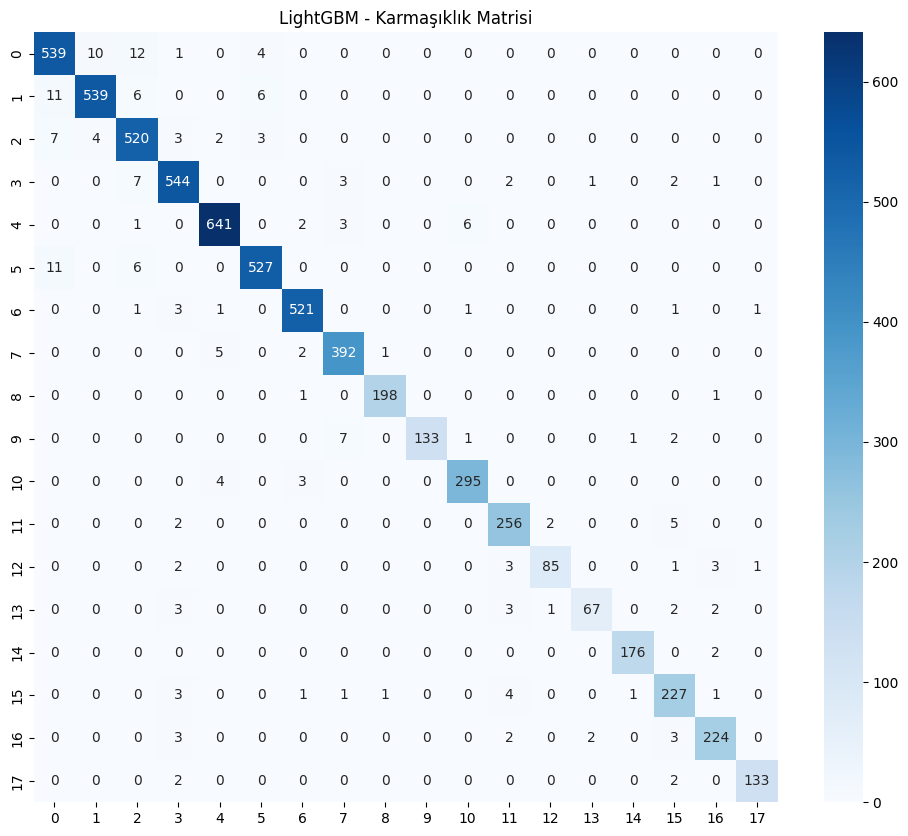

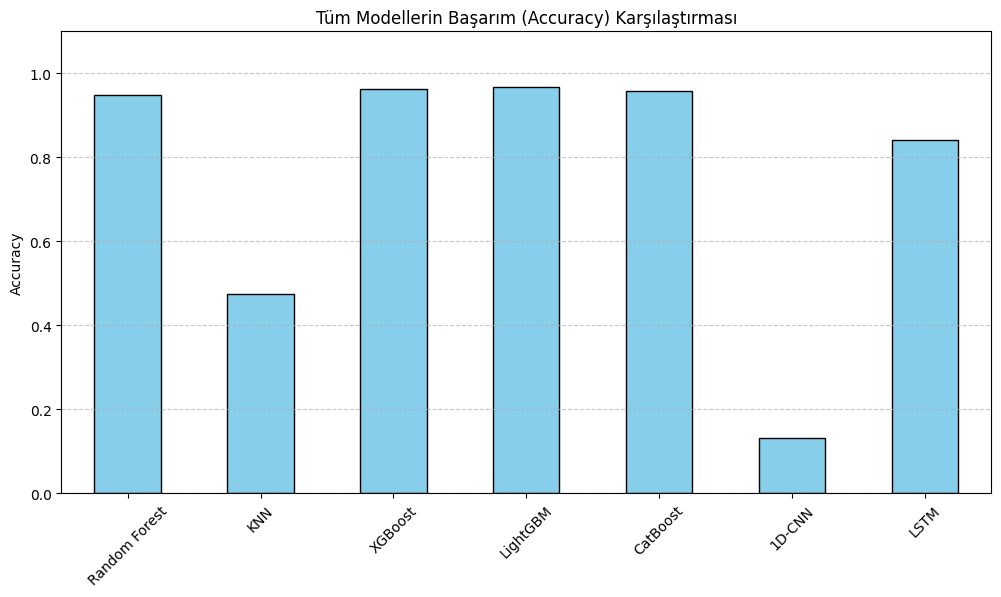

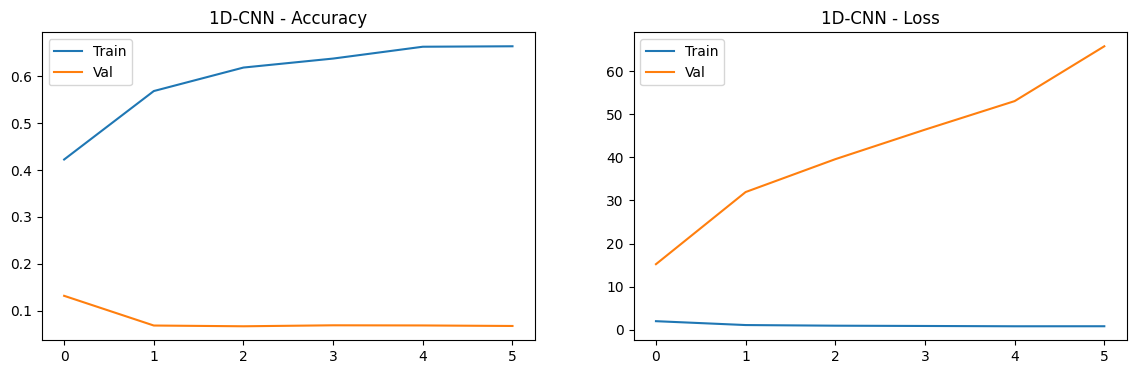

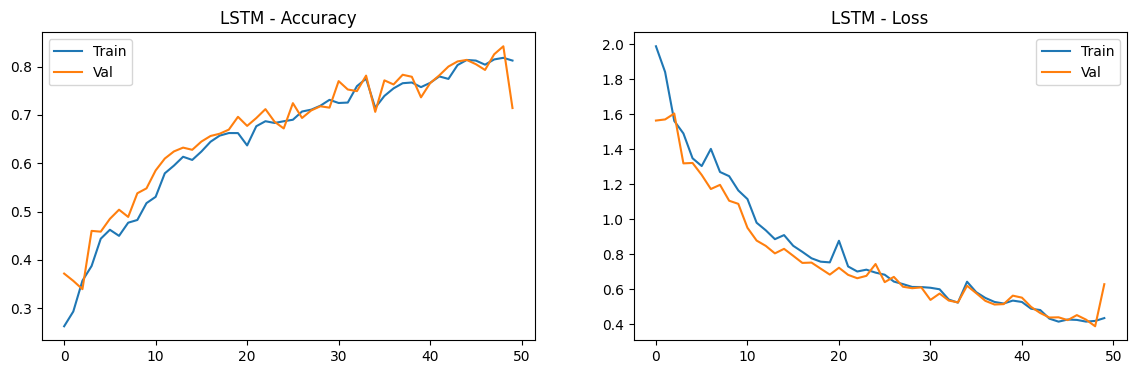

In [8]:
plt.figure(figsize=(12, 10))
y_pred_rf = models['LightGBM'].predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('LightGBM - Karmaşıklık Matrisi')
plt.show()

cnn_acc = max(history_cnn.history['val_accuracy'])
lstm_acc = max(history_lstm.history['val_accuracy'])

results_df.loc['1D-CNN'] = [cnn_acc, cnn_acc]
results_df.loc['LSTM'] = [lstm_acc, lstm_acc]

plt.figure(figsize=(12, 6))
results_df['Accuracy'].plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Tüm Modellerin Başarım (Accuracy) Karşılaştırması')
plt.ylabel('Accuracy')
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

def plot_training(history, name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

    ax1.plot(history.history['accuracy'], label='Train')
    ax1.plot(history.history['val_accuracy'], label='Val')
    ax1.set_title(f'{name} - Accuracy')
    ax1.legend()

    ax2.plot(history.history['loss'], label='Train')
    ax2.plot(history.history['val_loss'], label='Val')
    ax2.set_title(f'{name} - Loss')
    ax2.legend()
    plt.show()

plot_training(history_cnn, '1D-CNN')
plot_training(history_lstm, 'LSTM')

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Dropout, BatchNormalization, Dense, GRU, Bidirectional, Multiply, GlobalAveragePooling1D, Activation, Permute
from tensorflow.keras.models import Model

def attention_block(inputs, time_steps):
    a = Permute((2, 1))(inputs)

    a = Dense(time_steps, activation='softmax')(a)

    a_probs = Permute((2, 1))(a)

    output_attention_mul = Multiply()([inputs, a_probs])

    return output_attention_mul

def build_hybrid_model(input_shape, num_classes):
    inputs = Input(shape=input_shape)

    x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.3)(x)

    x = Conv1D(filters=128, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.3)(x)

    x = Conv1D(filters=256, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.3)(x)

    x = Bidirectional(GRU(128, return_sequences=True))(x)
    x = Dropout(0.4)(x)

    current_time_steps = x.shape[1]

    x = attention_block(x, current_time_steps)

    x = GlobalAveragePooling1D()(x)

    x = Dense(128, activation='relu')(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs, name="Hybrid_CNN_GRU_Attention")
    return model

input_shape = (300, 6)
num_classes = y_train_cat.shape[1]

model_hybrid = build_hybrid_model(input_shape, num_classes)
model_hybrid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("✅ Hibrit Model hatasız oluşturuldu.")
model_hybrid.summary()

✅ Hibrit Model hatasız oluşturuldu.


Model: "Hybrid_CNN_GRU_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 300, 6)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 300, 64)   │      1,216 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 300, 64)   │        256 │ conv1d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_8     │ (None, 150, 64)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 150, 64)   │          0 │ max_pooling1d_8[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 150, 128)  │     24,704 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 150, 128)  │        512 │ conv1d_9[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_9     │ (None, 75, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 75, 128)   │          0 │ max_pooling1d_9[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 75, 256)   │     98,560 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 75, 256)   │      1,024 │ conv1d_10[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_10    │ (None, 37, 256)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 37, 256)   │          0 │ max_pooling1d_10… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 37, 256)   │    296,448 │ dropout_13[0][0]  │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 37, 256)   │          0 │ bidirectional_2[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 256, 37)   │          0 │ dropout_14[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256, 37)   │      1,406 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_1 (Permute) │ (None, 37, 256)   │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 37, 256)   │          0 │ dropout_14[0][0]

 Total params: 459,344 (1.75 MB)

 Trainable params: 458,448 (1.75 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=0.00001, verbose=1)

print("🚀 Hibrit Model (CNN-GRU-Attention) Eğitiliyor...")

history_hybrid = model_hybrid.fit(
    X_train_dl, y_train_cat,
    epochs=30,
    batch_size=64,
    validation_data=(X_test_dl, y_test_cat),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

🚀 Hibrit Model (CNN-GRU-Attention) Eğitiliyor...
Not: Bu model daha karmaşık olduğu için epoch başına süre biraz artabilir.
Epoch 1/30
227/227 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.2232 - loss: 2.3193 - val_accuracy: 0.0850 - val_loss: 4.4699 - learning_rate: 0.0010
Epoch 2/30
227/227 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.4242 - loss: 1.4431 - val_accuracy: 0.0877 - val_loss: 6.1229 - learning_rate: 0.0010
Epoch 3/30
227/227 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.5603 - loss: 1.1204 - val_accuracy: 0.0877 - val_loss: 6.9631 - learning_rate: 0.0010
Epoch 4/30
225/227 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6116 - loss: 0.9631
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
227/227 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.6117 - loss: 0.9629 - val_accuracy: 0.0880 - val_loss: 7.1948 - learning_rate: 0.0010
Epoch 5/30
227/227 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.6576 - loss: 0.8513 - val_accuracy: 0.0877 -

Hibrit Model En İyi Doğruluk: 0.0882

--- NİHAİ PERFORMANS TABLOSU ---
                       Accuracy  F1 Score
LightGBM               0.966586  0.966555
XGBoost                0.962731  0.962715
CatBoost               0.959036  0.959001
Random Forest          0.947470  0.947333
LSTM                   0.842088  0.842088
KNN                    0.473735  0.476223
1D-CNN                 0.131406  0.131406
Hybrid (CNN-GRU-Attn)  0.088193  0.088193


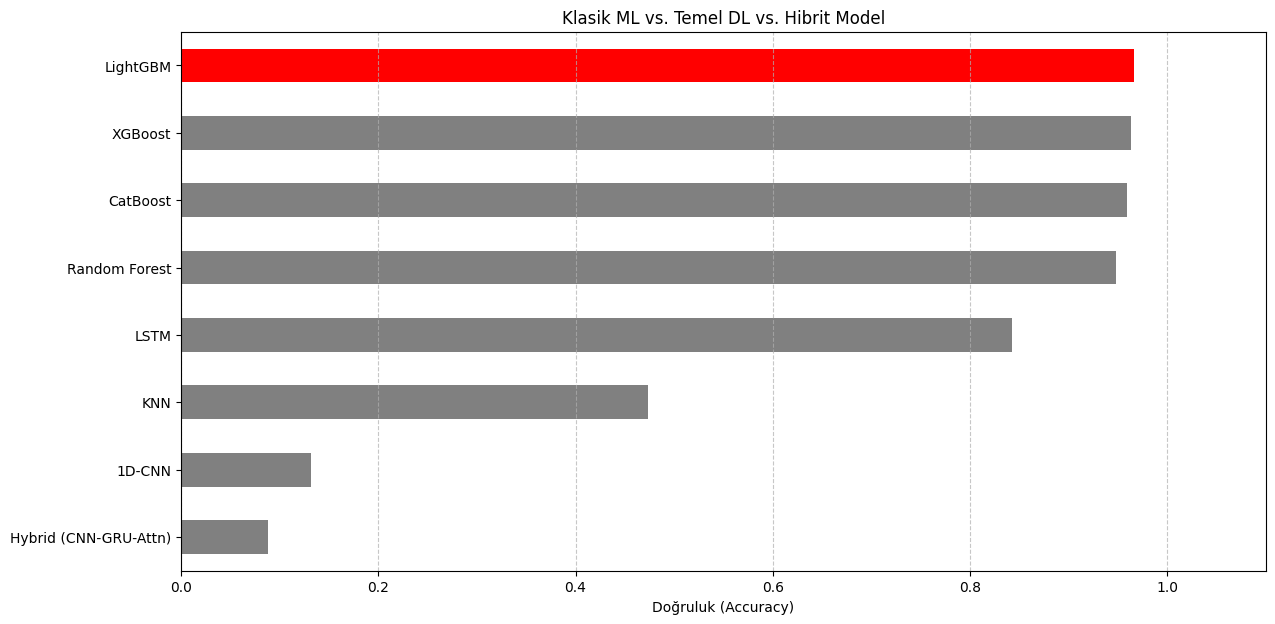

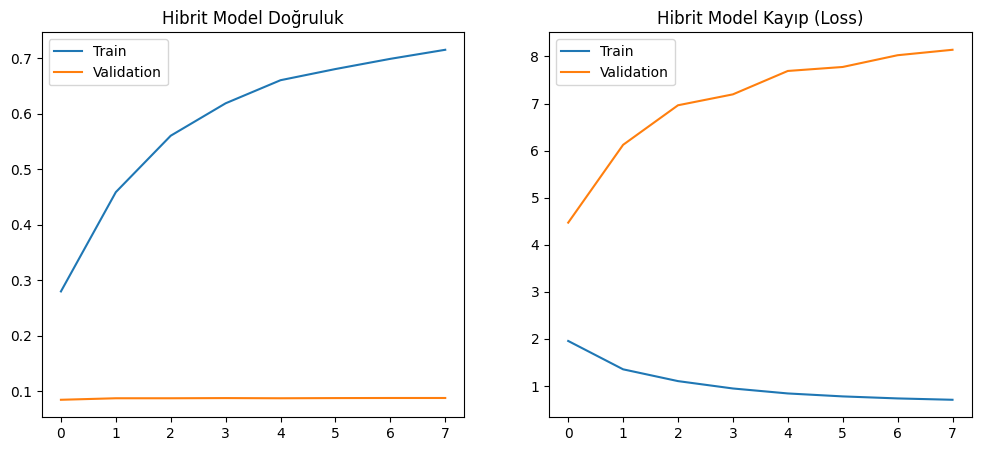

In [14]:
hybrid_acc = max(history_hybrid.history['val_accuracy'])
print(f"Hibrit Model En İyi Doğruluk: {hybrid_acc:.4f}")

try:
    results_df.loc['Hybrid (CNN-GRU-Attn)'] = [hybrid_acc, hybrid_acc]
except:
    pass

print("\n--- NİHAİ PERFORMANS TABLOSU ---")
print(results_df.sort_values(by='Accuracy', ascending=False))

plt.figure(figsize=(14, 7))
colors = ['gray'] * (len(results_df) - 1) + ['red']
results_df['Accuracy'].sort_values().plot(kind='barh', color=colors)
plt.title('Klasik ML vs. Temel DL vs. Hibrit Model')
plt.xlabel('Doğruluk (Accuracy)')
plt.xlim(0, 1.1)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_hybrid.history['accuracy'], label='Train')
plt.plot(history_hybrid.history['val_accuracy'], label='Validation')
plt.title('Hibrit Model Doğruluk')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_hybrid.history['loss'], label='Train')
plt.plot(history_hybrid.history['val_loss'], label='Validation')
plt.title('Hibrit Model Kayıp (Loss)')
plt.legend()
plt.show()

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Layer, Dense, Dropout, Input, Reshape, Lambda, Permute, Multiply, GlobalAveragePooling1D, GRU, Bidirectional

# 6 Düğümümüz var: 0:Ax, 1:Ay, 2:Az, 3:Gx, 4:Gy, 5:Gz
# 1 = Bağlı, 0 = Bağlı Değil

# Başlangıç matrisi (Birim matris - Herkes kendine bağlı)
A = np.eye(6)

# İvmeölçer kendi içinde bağlı (Ax-Ay, Ay-Az, Ax-Az...)
A[0, 1] = A[1, 0] = 1
A[1, 2] = A[2, 1] = 1
A[0, 2] = A[2, 0] = 1

# Jiroskop kendi içinde bağlı
A[3, 4] = A[4, 3] = 1
A[4, 5] = A[5, 4] = 1
A[3, 5] = A[5, 3] = 1

# İvmeölçer ve Jiroskop Karşılıklı Bağlı (Ax-Gx, Ay-Gy...)
A[0, 3] = A[3, 0] = 1
A[1, 4] = A[4, 1] = 1
A[2, 5] = A[5, 2] = 1

print("Sensör İlişki Matrisi (Adjacency Matrix):\n", A)

D = np.diag(np.sum(A, axis=1))
D_inv_sqrt = np.linalg.inv(np.sqrt(D))
A_normalized = np.dot(np.dot(D_inv_sqrt, A), D_inv_sqrt)

A_tensor = tf.constant(A_normalized, dtype=tf.float32)
print("\nNormalize Edilmiş Matris Hazır.")

Sensör İlişki Matrisi (Adjacency Matrix):
 [[1. 1. 1. 1. 0. 0.]
 [1. 1. 1. 0. 1. 0.]
 [1. 1. 1. 0. 0. 1.]
 [1. 0. 0. 1. 1. 1.]
 [0. 1. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1. 1.]]

Normalize Edilmiş Matris Hazır.


In [16]:
import tensorflow as tf
from tensorflow.keras.layers import Layer, Input, Dense, Dropout, Reshape, GlobalAveragePooling1D, GRU, Bidirectional, Multiply, Permute
from tensorflow.keras.models import Model

class GraphConv1D(Layer):
    def __init__(self, adj_matrix, filters, activation='relu', **kwargs):
        super(GraphConv1D, self).__init__(**kwargs)
        self.adj_matrix = adj_matrix
        self.filters = filters
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        if len(input_shape) == 3:
            feature_dim = 1
        else:
            feature_dim = input_shape[-1]

        self.kernel = self.add_weight(name='kernel',
                                      shape=(feature_dim, self.filters),
                                      initializer='glorot_uniform',
                                      trainable=True)

        self.bias = self.add_weight(name='bias',
                                    shape=(self.filters,),
                                    initializer='zeros',
                                    trainable=True)
        super(GraphConv1D, self).build(input_shape)

    def call(self, inputs):
        if len(inputs.shape) == 3:
            x = tf.expand_dims(inputs, axis=-1)
        else:
            x = inputs

        output = tf.matmul(x, self.kernel)

        output = tf.einsum('nm,btmf->btnf', self.adj_matrix, output)

        if self.bias is not None:
            output += self.bias

        return self.activation(output)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1], input_shape[2], self.filters)

    def get_config(self):
        config = super(GraphConv1D, self).get_config()
        config.update({"filters": self.filters})
        return config

print("GCN Katmanı Hazır.")

GCN Katmanı Hazır.


In [17]:
def build_gcn_hybrid_model(input_shape, num_classes, adj_matrix):
    inputs = Input(shape=input_shape)
    x = GraphConv1D(adj_matrix=adj_matrix, filters=32, activation='relu')(inputs)
    x = Dropout(0.3)(x)

    x = GraphConv1D(adj_matrix=adj_matrix, filters=64, activation='relu')(x)
    x = Dropout(0.3)(x)

    nodes = input_shape[1]
    filters = 64
    target_dim = nodes * filters

    x = Reshape((-1, target_dim))(x)

    x = Bidirectional(GRU(128, return_sequences=True))(x)
    x = Dropout(0.4)(x)

    time_steps = input_shape[0] # 300
    x = attention_block(x, time_steps)

    x = GlobalAveragePooling1D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs, name="GCN_GRU_Attention_Model")
    return model

model_gcn = build_gcn_hybrid_model(input_shape=(300, 6), num_classes=num_classes, adj_matrix=A_tensor)
model_gcn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("GCN Modeli Başarıyla Derlendi.")
model_gcn.summary()

GCN Modeli Başarıyla Derlendi.


Model: "GCN_GRU_Attention_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 300, 6)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_conv1d        │ (None, 300, 6,    │         64 │ input_layer_5[0]… │
│ (GraphConv1D)       │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 300, 6,    │          0 │ graph_conv1d[0][… │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_conv1d_1      │ (None, 300, 6,    │      2,112 │ dropout_16[0][0]  │
│ (GraphConv1D)       │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 300, 6,    │          0 │ graph_conv1d_1[0… │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 300, 384)  │          0 │ dropout_17[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 300, 256)  │    394,752 │ reshape[0][0]     │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 300, 256)  │          0 │ bidirectional_3[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_2 (Permute) │ (None, 256, 300)  │          0 │ dropout_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 256, 300)  │     90,300 │ permute_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_3 (Permute) │ (None, 300, 256)  │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 300, 256)  │          0 │ dropout_18[0][0], │
│ (Multiply)          │                   │            │ permute_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ multiply_1[0][0]  │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 128)       │     32,896 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_19          │ (None, 128)       │          0 │ dense_8[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 18)        │      2,322 │ dropout_19[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 522,446 (1.99 MB)

 Trainable params: 522,446 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

🚀 GCN Tabanlı Hibrit Model Eğitiliyor...
Epoch 1/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/step - accuracy: 0.1156 - loss: 2.7161 - val_accuracy: 0.2337 - val_loss: 2.0753 - learning_rate: 0.0010
Epoch 2/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 15s 67ms/step - accuracy: 0.2215 - loss: 1.9677 - val_accuracy: 0.2251 - val_loss: 1.8678 - learning_rate: 0.0010
Epoch 3/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 15s 67ms/step - accuracy: 0.2366 - loss: 1.8186 - val_accuracy: 0.2387 - val_loss: 1.7991 - learning_rate: 0.0010
Epoch 4/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 16s 71ms/step - accuracy: 0.2602 - loss: 1.7429 - val_accuracy: 0.2612 - val_loss: 1.7432 - learning_rate: 0.0010
Epoch 5/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 15s 67ms/step - accuracy: 0.3011 - loss: 1.6878 - val_accuracy: 0.3107 - val_loss: 1.6905 - learning_rate: 0.0010
Epoch 6/50
227/227 ━━━━━━━━━━━━━━━━━━━━ 15s 67ms/step - accuracy: 0.3108 - loss: 1.6555 - val_accuracy: 0.3030 - val_loss: 1.6990 - learning_rate: 0.0010
Epoch 7/50
227/227 ━━━━━━━━━━━━━━━━

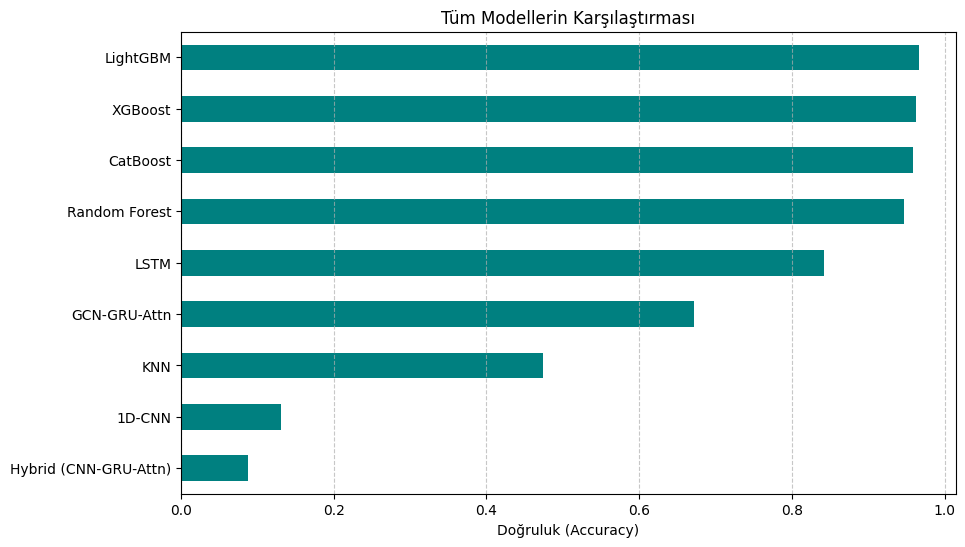

In [ ]:
print("GCN Tabanlı Hibrit Model Eğitiliyor...")

history_gcn = model_gcn.fit(
    X_train_dl, y_train_cat,
    epochs=50,
    batch_size=64,
    validation_data=(X_test_dl, y_test_cat),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

gcn_acc = max(history_gcn.history['val_accuracy'])
print(f"GCN Model En İyi Doğruluk: {gcn_acc:.4f}")

try:
    results_df.loc['GCN-GRU-Attn'] = [gcn_acc, gcn_acc]
except:
    pass

plt.figure(figsize=(10, 6))
results_df['Accuracy'].sort_values().plot(kind='barh', color='teal')
plt.title('Tüm Modellerin Karşılaştırması')
plt.xlabel('Doğruluk (Accuracy)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

1/4: Latent Space t-SNE hesaplanıyor...


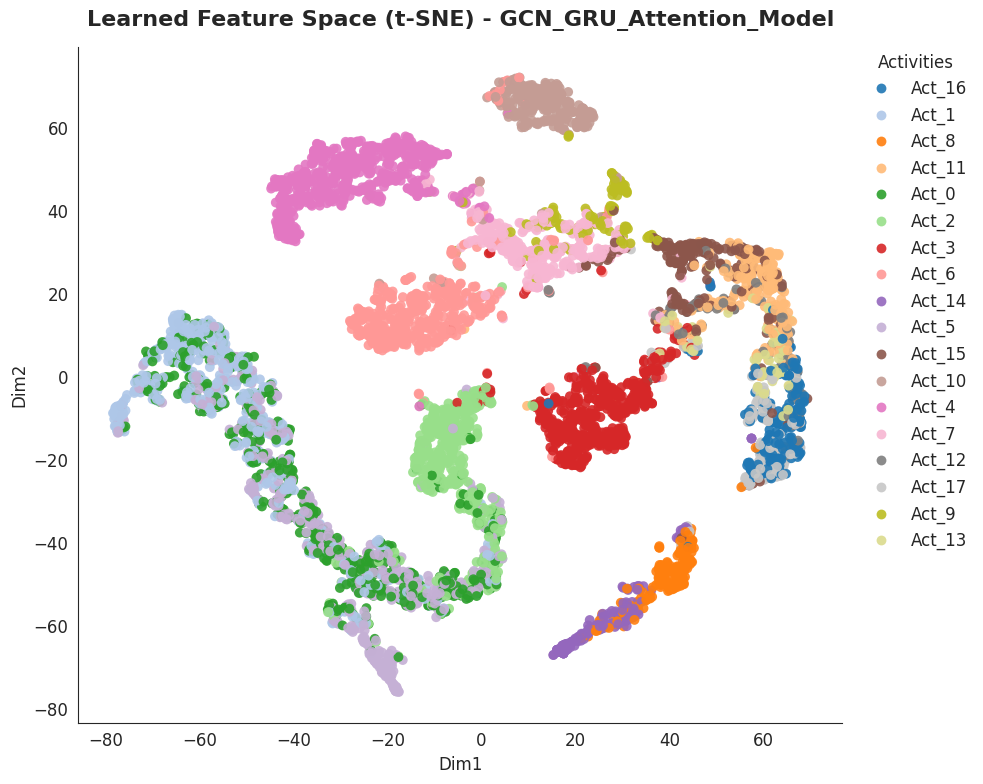

2/4: Özellik Önem Analizi (LightGBM Referanslı)...


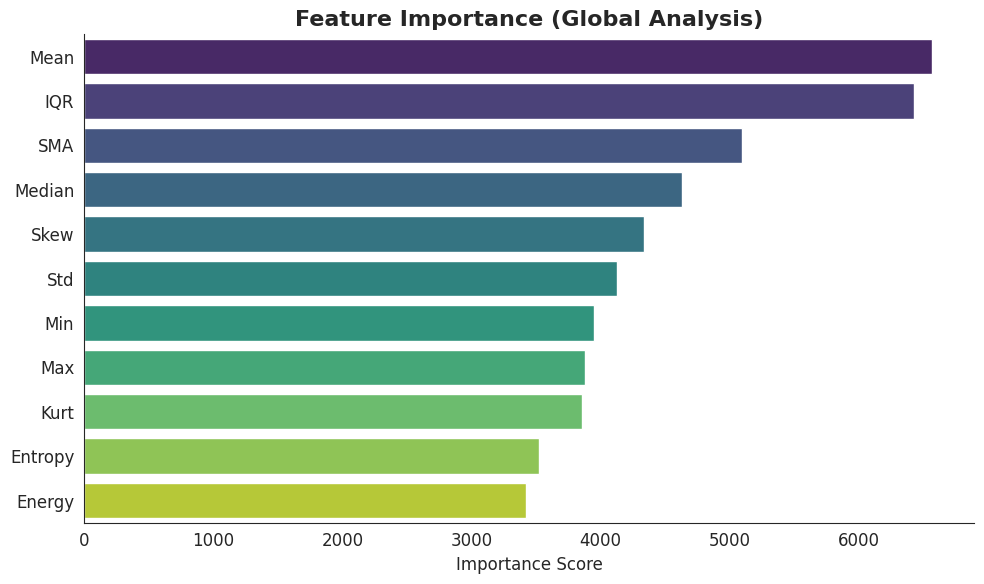

3/4: Sınıf Bazlı F1-Skorları...


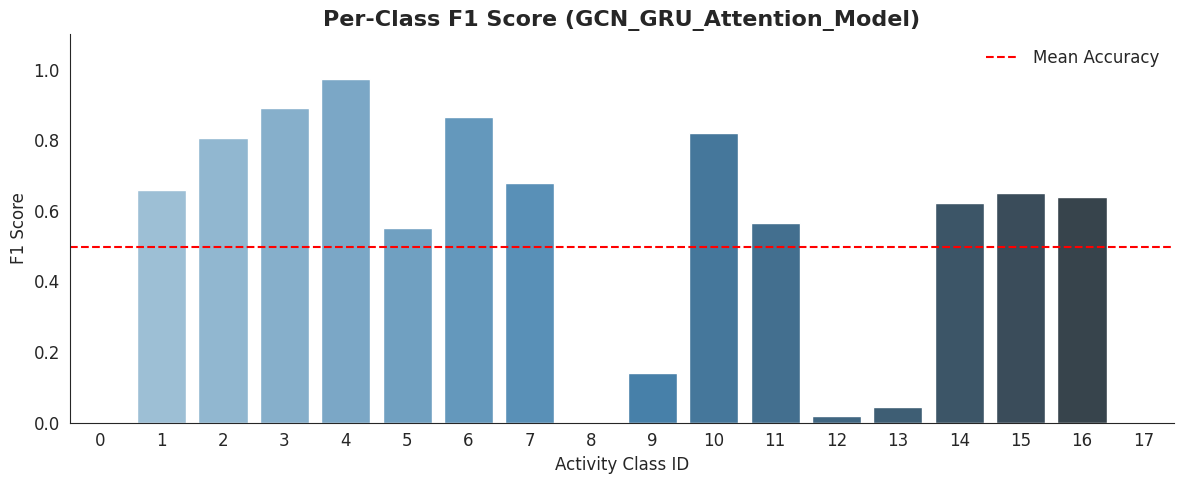

4/4: Karmaşıklık Matrisi...


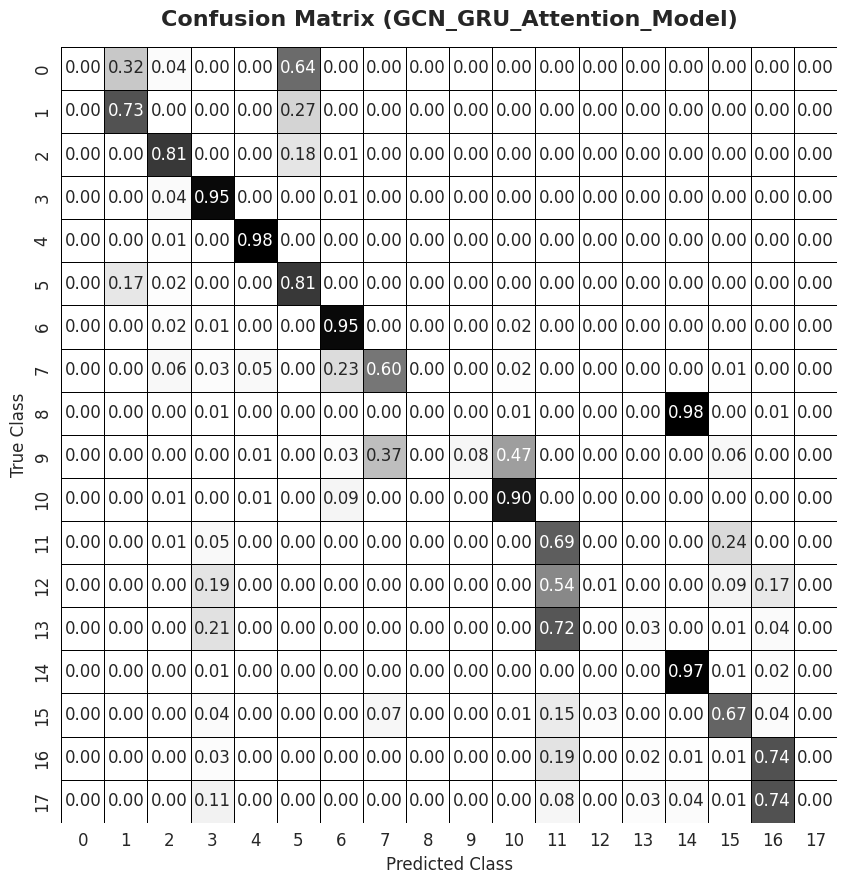

Tüm görseller başarıyla oluşturuldu.


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Model

target_model = model_gcn
feature_model = models["LightGBM"]

sns.set_style("white")
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 12})

print("1/4: Latent Space t-SNE hesaplanıyor...")

layer_name = None
for layer in reversed(target_model.layers):
    if isinstance(layer, tf.keras.layers.Dense) and layer.activation.__name__ == 'relu':
        layer_name = layer.name
        break
if not layer_name: layer_name = target_model.layers[-2].name

feature_extractor = Model(inputs=target_model.input, outputs=target_model.get_layer(layer_name).output)
embeddings = feature_extractor.predict(X_test_dl, verbose=0)

tsne = TSNE(n_components=2, perplexity=40, early_exaggeration=12, learning_rate=200, n_iter=1000, init='pca', random_state=42)
tsne_result = tsne.fit_transform(embeddings)

df_tsne = pd.DataFrame(tsne_result, columns=['Dim1', 'Dim2'])
df_tsne['Class_ID'] = np.argmax(y_test_cat, axis=1)
df_tsne['Activity'] = df_tsne['Class_ID'].apply(lambda x: f"Act_{x}")

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x="Dim1", y="Dim2", hue="Activity",
    palette=sns.color_palette("tab20", len(np.unique(df_tsne['Class_ID']))),
    data=df_tsne, legend="full", alpha=0.9, s=50, edgecolor='none'
)
plt.title(f'Learned Feature Space (t-SNE) - {target_model.name}', fontsize=16, fontweight='bold', pad=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., title="Activities", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

print("2/4: Özellik Önem Analizi (LightGBM Referanslı)...")

raw_importance = feature_model.feature_importances_
feature_names = X_features_df.columns
df_imp = pd.DataFrame({'Feature_Name': feature_names, 'Importance': raw_importance})
df_imp['Feature_Type'] = df_imp['Feature_Name'].apply(lambda x: x.split('_')[-1])
df_imp_grouped = df_imp.groupby('Feature_Type')['Importance'].sum().reset_index().sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature_Type", data=df_imp_grouped, palette="viridis")
plt.title('Feature Importance (Global Analysis)', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('')
sns.despine()
plt.tight_layout()
plt.show()

print("3/4: Sınıf Bazlı F1-Skorları...")

y_pred_probs = target_model.predict(X_test_dl, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_cat, axis=1)

report = classification_report(y_true, y_pred, output_dict=True)
class_scores = {k: v['f1-score'] for k, v in report.items() if k.isdigit()}

plt.figure(figsize=(12, 5))
sns.barplot(x=list(class_scores.keys()), y=list(class_scores.values()), palette="Blues_d")
plt.title(f'Per-Class F1 Score ({target_model.name})', fontsize=16, fontweight='bold')
plt.xlabel('Activity Class ID')
plt.ylabel('F1 Score')
plt.ylim(0, 1.1)
plt.axhline(y=np.mean(list(class_scores.values())), color='red', linestyle='--', label='Mean Accuracy')
plt.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

print("4/4: Karmaşıklık Matrisi...")

cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 9))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greys', cbar=False,
            linewidths=0.5, linecolor='black', square=True)
plt.title(f'Confusion Matrix ({target_model.name})', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

print("Tüm görseller başarıyla oluşturuldu.")


TÜM MODELLERİN PERFORMANS TABLOSU


,Accuracy,F1-Score,Precision,Recall
Model,,,,
LightGBM,0.9666,0.9666,0.9668,0.9666
XGBoost,0.9627,0.9627,0.9630,0.9627
CatBoost,0.9590,0.9590,0.9592,0.9590
Random Forest,0.9475,0.9473,0.9480,0.9475
LSTM,0.8421,0.8335,0.8660,0.8421
KNN,0.4737,0.4762,0.5049,0.4737
1D-CNN,0.1314,0.0486,0.0646,0.1314
Hybrid (CNN-GRU),0.0850,0.0134,0.0073,0.0850


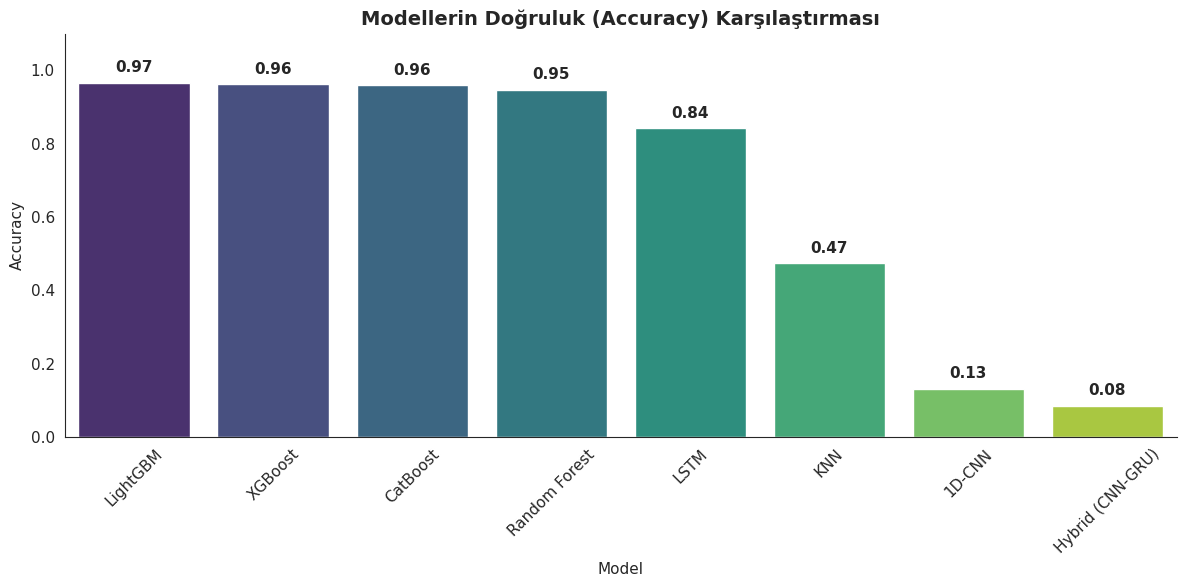


🔍 LIGHTGBM DETAYLI ANALİZİ


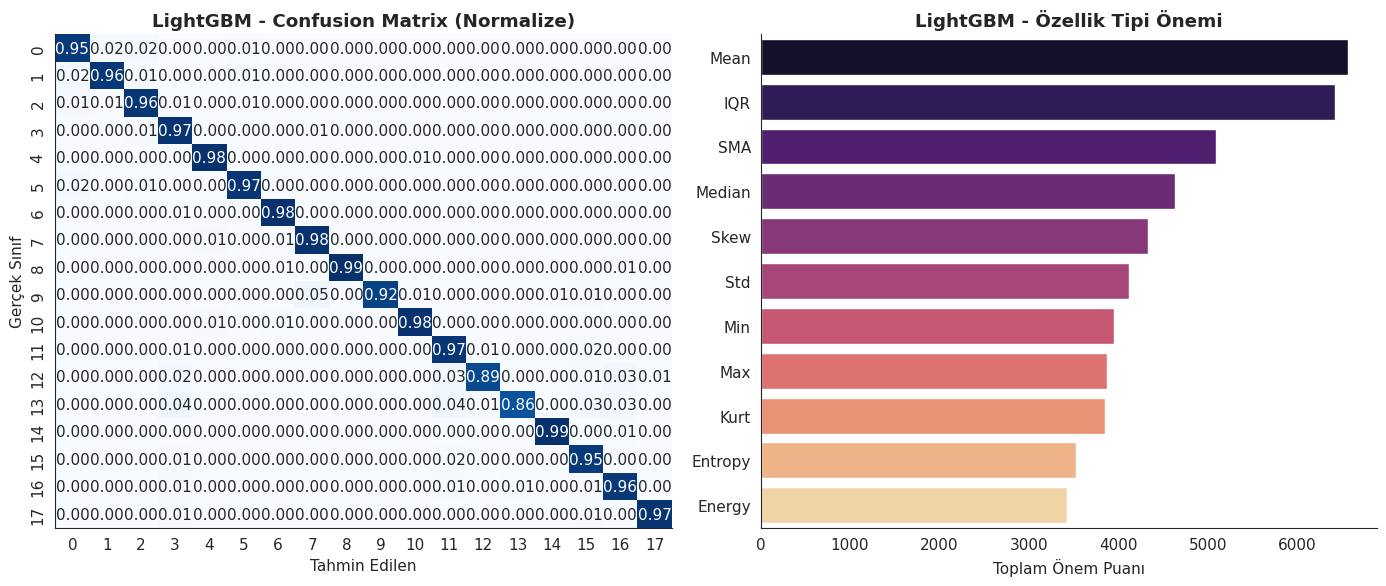


LightGBM - Sınıf Bazlı Performans Raporu:
              precision    recall  f1-score   support

           0     0.9489    0.9523    0.9506       566
           1     0.9747    0.9591    0.9668       562
           2     0.9403    0.9647    0.9524       539
           3     0.9611    0.9714    0.9663       560
           4     0.9816    0.9816    0.9816       653
           5     0.9759    0.9688    0.9723       544
           6     0.9830    0.9849    0.9839       529
           7     0.9655    0.9800    0.9727       400
           8     0.9900    0.9900    0.9900       200
           9     1.0000    0.9236    0.9603       144
          10     0.9736    0.9768    0.9752       302
          11     0.9481    0.9660    0.9570       265
          12     0.9659    0.8947    0.9290        95
          13     0.9571    0.8590    0.9054        78
          14     0.9888    0.9888    0.9888       178
          15     0.9265    0.9498    0.9380       239
          16     0.9573    0.9573    0

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

sns.set_style("white")
plt.rcParams.update({'font.size': 11})

final_metrics = []

if 'models' in locals():
    for name, model in models.items():
        try:
            y_pred = model.predict(X_test_scaled)
            acc = accuracy_score(y_test, y_pred)
            f1 = f1_score(y_test, y_pred, average='weighted')
            prec = precision_score(y_test, y_pred, average='weighted')
            rec = recall_score(y_test, y_pred, average='weighted')
            final_metrics.append({"Model": name, "Accuracy": acc, "F1-Score": f1, "Precision": prec, "Recall": rec})
        except Exception as e:
            print(f"⚠️ {name} değerlendirilemedi: {e}")

dl_models = [
    ('1D-CNN', 'model_cnn'),
    ('LSTM', 'model_lstm'),
    ('Hybrid (CNN-GRU)', 'model_hybrid'),
    ('GCN (Graph Conv)', 'model_gcn_opt')
]

for name, var_name in dl_models:
    if var_name in locals():
        try:
            model_obj = locals()[var_name]
            y_pred_probs = model_obj.predict(X_test_dl, verbose=0)
            y_pred_dl = np.argmax(y_pred_probs, axis=1)
            y_true_dl = np.argmax(y_test_cat, axis=1) # One-hot'tan geri dön

            acc = accuracy_score(y_true_dl, y_pred_dl)
            f1 = f1_score(y_true_dl, y_pred_dl, average='weighted')
            prec = precision_score(y_true_dl, y_pred_dl, average='weighted')
            rec = recall_score(y_true_dl, y_pred_dl, average='weighted')
            final_metrics.append({"Model": name, "Accuracy": acc, "F1-Score": f1, "Precision": prec, "Recall": rec})
        except Exception as e:
            pass

results_df = pd.DataFrame(final_metrics).set_index("Model")
results_df = results_df.sort_values(by="Accuracy", ascending=False)

print("\nTÜM MODELLERİN PERFORMANS TABLOSU")
display(results_df.style.background_gradient(cmap="Greens", subset=["Accuracy", "F1-Score"]).format("{:.4f}"))

plt.figure(figsize=(12, 6))
sns.barplot(x=results_df.index, y=results_df["Accuracy"], palette="viridis")
plt.title("Modellerin Doğruluk (Accuracy) Karşılaştırması", fontsize=14, fontweight='bold')
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.ylim(0, 1.1)
for i, v in enumerate(results_df["Accuracy"]):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', va='bottom', fontweight='bold')
sns.despine()
plt.tight_layout()
plt.show()

if "LightGBM" in models:
    print("\n🔍 LIGHTGBM DETAYLI ANALİZİ")
    lgbm_model = models["LightGBM"]
    y_pred_lgbm = lgbm_model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred_lgbm)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # Normalize

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=range(18), yticklabels=range(18))
    plt.title("LightGBM - Confusion Matrix (Normalize)", fontweight='bold')
    plt.xlabel("Tahmin Edilen")
    plt.ylabel("Gerçek Sınıf")

    plt.subplot(1, 2, 2)
    raw_imp = lgbm_model.feature_importances_
    feat_names = X_features_df.columns
    df_imp = pd.DataFrame({'Feature': feat_names, 'Value': raw_imp})
    df_imp['Type'] = df_imp['Feature'].apply(lambda x: x.split('_')[-1])
    df_imp_grouped = df_imp.groupby('Type')['Value'].sum().reset_index().sort_values(by='Value', ascending=False)

    sns.barplot(x="Value", y="Type", data=df_imp_grouped, palette="magma")
    plt.title("LightGBM - Özellik Tipi Önemi", fontweight='bold')
    plt.xlabel("Toplam Önem Puanı")
    plt.ylabel("")

    sns.despine()
    plt.tight_layout()
    plt.show()

    print("\nLightGBM - Sınıf Bazlı Performans Raporu:")
    print(classification_report(y_test, y_pred_lgbm, digits=4))

print("Final Raporlama Tamamlandı.")